In [2]:
# Load the three file formats into pandas DataFrames.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

csv_data = pd.read_csv('sales_part1.csv')
excel_data = pd.read_excel('sales_part2.xlsx')
json_data = pd.read_json('sales_part3.json')
for data in [csv_data, excel_data, json_data]:
    print('Shape:', data.shape)
    display(data.head(2))
    display(data.isna().sum())

Shape: (3600, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.0,0.0,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.0,219.5820


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      1
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Shape: (3600, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,3601,CA-2018-138310,6/26/2018,6/30/2018,Standard Class,NP-18700,Nora Preis,Consumer,United States,Denver,...,80219.0,West,TEC-AC-10001990,Technology,Accessories,Kensington Orbit Wireless Mobile Trackball for...,431.928,9,0.2,64.7892
1,3602,CA-2015-159835,11/17/2015,11/24/2015,Standard Class,RB-19330,Randy Bradley,Consumer,United States,Philadelphia,...,19143.0,East,OFF-PA-10002137,Office Supplies,Paper,"Southworth 100% RÃ©sumÃ© Paper, 24lb.",12.448,2,0.2,3.8900


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      1
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Shape: (3600, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,7201,CA-2017-104276,11/27/2017,12/3/2017,Standard Class,HF-14995,Herbert Flentye,Consumer,United States,Fort Lauderdale,...,33311.0,South,TEC-PH-10001944,Technology,Phones,Wi-Ex zBoost YX540 Cellular Phone Signal Booster,116.760,1.0,0.20,14.5950
1,7202,CA-2017-104276,11/27/2017,12/3/2017,Standard Class,HF-14995,Herbert Flentye,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10001039,Furniture,Tables,KI Adjustable-Height Table,331.023,7.0,0.45,-114.3534


Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      815
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

In [16]:
sales=pd.concat([csv_data,excel_data,json_data],ignore_index=True)
sales.columns=sales.columns.str.strip()
for column in ['Region','Category','Sub-Category']:
    sales[column]=sales[column].str.strip().str.title()

sales['Order Date']=pd.to_datetime(sales['Order Date'],errors='coerce')
sales['Sales']=pd.to_numeric(sales['Sales'],errors='coerce')
sales['Quantity'] = pd.to_numeric(sales['Quantity'], errors='coerce')
sales = sales.drop_duplicates(subset='Row ID')
sales = sales.dropna(subset=['Order ID', 'Order Date', 'Sales', 'Quantity'])
sales['Category'] = sales['Category'].fillna('Unknown')
sales['Region'] = sales['Region'].fillna('Unknown')
print('Cleaned shape:', sales.shape)

Cleaned shape: (9994, 21)


In [18]:
# Derive unit sales value and order month for analysis.
sales['Unit Price'] = sales['Sales'].div(sales['Quantity'].replace(0, float('nan')))
sales['Order Month'] = sales['Order Date'].dt.month.astype(str)
display(sales[['Order ID', 'Sales', 'Quantity', 'Unit Price', 'Order Month']].head())

,Order ID,Sales,Quantity,Unit Price,Order Month
0,CA-2017-152156,261.9600,2.0,130.9800,11
1,CA-2017-152156,731.9400,3.0,243.9800,11
2,CA-2017-138688,14.6200,2.0,7.3100,6
3,US-2016-108966,957.5775,5.0,191.5155,10
4,US-2016-108966,22.3680,2.0,11.1840,10


In [20]:
# Calculate descriptive statistics, total sales and average value per order.
display(sales[['Sales', 'Quantity', 'Unit Price']].describe())
print('Total sales:', round(sales['Sales'].sum(), 2))
order_totals = sales.groupby('Order ID')['Sales'].sum()
print('Average order value:', round(order_totals.mean(), 2))
category_sales = sales.groupby('Category')['Sales'].sum()
display(category_sales)
display(sales['Category'].value_counts())

,Sales,Quantity,Unit Price
count,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,60.919569
std,623.245101,2.225110,142.927440
min,0.444000,1.000000,0.336000
25%,17.280000,2.000000,5.470000
50%,54.490000,3.000000,16.270000
75%,209.940000,5.000000,63.940000
max,22638.480000,14.000000,3773.080000


Total sales: 2297200.86
Average order value: 458.61


Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

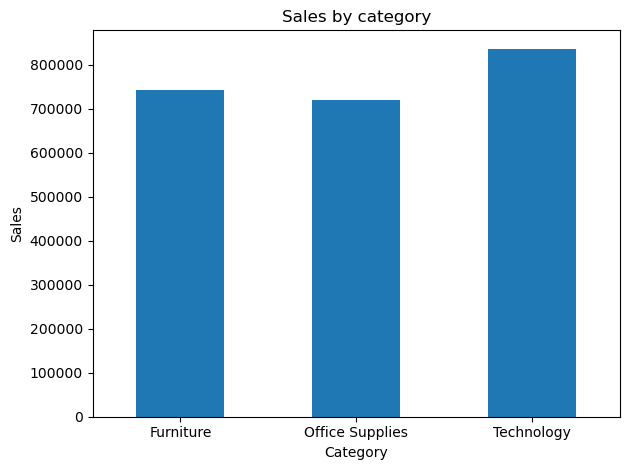

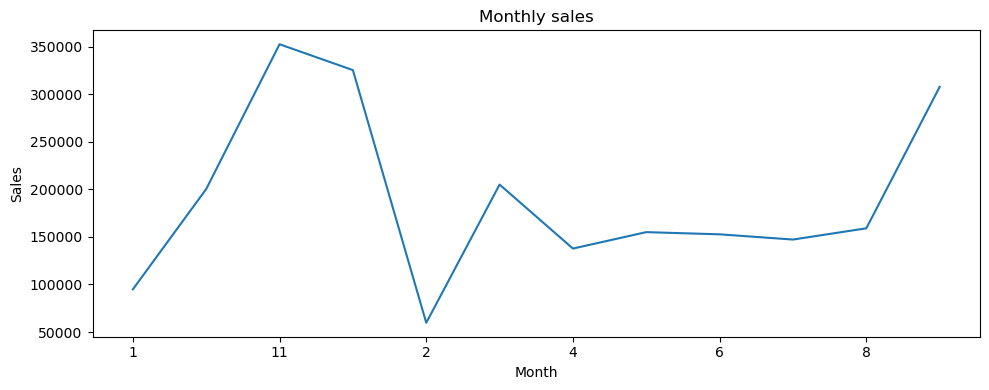

In [22]:
# Plot category sales and the monthly sales trend.
category_sales.plot(kind='bar', ylabel='Sales', title='Sales by category', rot=0)
plt.tight_layout()
plt.show()
sales.groupby('Order Month')['Sales'].sum().plot(
    figsize=(10, 4), xlabel='Month', ylabel='Sales', title='Monthly sales')
plt.tight_layout()
plt.show()

In [24]:
# Save the unified cleaned dataset in the output folder.
Path('outputs').mkdir(exist_ok=True)
sales.to_csv('outputs/02_cleaned_sales.csv', index=False)